# PPO Run Toward the 98% BO Target

This notebook applies PPO to the same Haber-Bosch benchmark used by the BO and Dreamer notebooks.

To keep the reward target comparable, the environment is wrapped as a **single-step episode**: reset returns the BO-style zero observation, PPO proposes one 7D action, the flowsheet is evaluated once, and the episode ends immediately.

With that contract, a **hard 5000-episode limit** means a hard budget of 5000 flowsheet evaluations. Checkpoints and best-model snapshots are enabled because PPO will likely need multiple restarts.

In [1]:
from __future__ import annotations

import importlib
import json
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

import dreamerv3_haberbosch_helpers as dreamer_helpers

hb = importlib.reload(dreamer_helpers)
hb.set_plot_style()

WORKSPACE_DIR = hb.WORKSPACE_DIR
RUN_NAME = "ppo_haber_bosch_target98"
RUN_LOGDIR = WORKSPACE_DIR / "runs" / RUN_NAME
SEED = 7

BO_REFERENCE = {
    "reward": 2712.651793,
    "normalized_action": np.array(
        [
            -0.6127335418989747,
            0.08136597881754437,
            0.6577094487733803,
            1.0,
            1.0,
            1.0,
            -1.0,
        ],
        dtype=np.float32,
    ),
}

SUCCESS_FRACTION = 0.98
SUCCESS_REWARD = SUCCESS_FRACTION * BO_REFERENCE["reward"]

MAX_EPISODES = 5_000
CHECKPOINT_EVERY_EPISODES = 250
EVAL_EVERY_EPISODES = 100
N_EVAL_EPISODES = 10
ANALYSIS_EVAL_EPISODES = 25
TRAIN_ROLLING_WINDOW = 50

PPO_DEVICE = "auto"
PPO_N_STEPS = 256
PPO_BATCH_SIZE = 64
PPO_N_EPOCHS = 10
PPO_GAMMA = 1.0
PPO_GAE_LAMBDA = 1.0
PPO_LEARNING_RATE = 3e-4
PPO_ENT_COEF = 0.01
PPO_CLIP_RANGE = 0.2
POLICY_HIDDEN_UNITS = (256, 256)

RESUME_FROM_LATEST = True
STOP_ON_TARGET_EVAL = True

pd.DataFrame(
    [
        {
            "bo_reward": BO_REFERENCE["reward"],
            "success_fraction": SUCCESS_FRACTION,
            "success_reward": SUCCESS_REWARD,
            "max_episodes": MAX_EPISODES,
            "checkpoint_every_episodes": CHECKPOINT_EVERY_EPISODES,
            "eval_every_episodes": EVAL_EVERY_EPISODES,
            "eval_episodes": N_EVAL_EPISODES,
            "ppo_n_steps": PPO_N_STEPS,
            "ppo_batch_size": PPO_BATCH_SIZE,
            "ppo_learning_rate": PPO_LEARNING_RATE,
            "resume_from_latest": RESUME_FROM_LATEST,
            "run_logdir": str(RUN_LOGDIR),
        }
    ]
)

,bo_reward,success_fraction,success_reward,max_episodes,checkpoint_every_episodes,eval_every_episodes,eval_episodes,ppo_n_steps,ppo_batch_size,ppo_learning_rate,resume_from_latest,run_logdir
0,2712.651793,0.98,2658.398757,5000,250,100,10,256,64,0.0003,True,/Users/campatzis/Documents/Research/runs/ppo_h...


In [2]:
def evaluate_normalized_action(environment, action: np.ndarray) -> dict[str, float | bool]:
    environment.reset()
    _, reward, terminated, truncated, info = environment.step(action)
    row: dict[str, float | bool] = {
        "reward": float(reward),
        "terminated": bool(terminated),
        "truncated": bool(truncated),
    }
    scaled = np.asarray(info.get("scaled_action", np.zeros_like(action)), dtype=np.float64)
    row.update({f"a{index}": float(action[index - 1]) for index in range(1, 8)})
    row.update({f"a{index}_physical": float(scaled[index - 1]) for index in range(1, 8)})
    for name, value in info.items():
        if name == "scaled_action":
            continue
        if isinstance(value, (int, float, np.integer, np.floating, bool)):
            row[name] = float(value) if not isinstance(value, bool) else bool(value)
    return row

preflight = hb.build_preflight_frame()
display(preflight)
if not preflight["ok"].all():
    missing = preflight.loc[~preflight["ok"], "item"].tolist()
    raise RuntimeError(f"Preflight failed for: {missing}")

env = hb.make_haber_bosch_env()
try:
    smoke_test = hb.run_smoke_test(env)
    bo_reference_row = evaluate_normalized_action(env, BO_REFERENCE["normalized_action"])
finally:
    env.close()

display(smoke_test.to_frame(name="value"))
baseline_frame = pd.DataFrame([bo_reference_row])
baseline_frame["bo_fraction"] = baseline_frame["reward"] / BO_REFERENCE["reward"]
baseline_frame["success_reward"] = SUCCESS_REWARD
display(
    baseline_frame[
        [
            "reward",
            "bo_fraction",
            "success_reward",
            "nh3_kg_per_s",
            "power_kw",
            "revenue_per_h",
            "energy_cost_per_h",
        ]
    ]
)

,item,value,ok
0,Workspace,/Users/campatzis/Documents/Research,True
1,Flowsheet,/Users/campatzis/Documents/Research/DWSIM Simu...,True
2,Bridge Script,/Users/campatzis/Documents/Research/.dwsim_sup...,True
3,Rosetta Wrapper,/Users/campatzis/Documents/Research/.venv311-r...,True
4,Rosetta Python,/Users/campatzis/Documents/Research/.venv311-r...,True
5,Mono Root,/Users/campatzis/Documents/Research/.mono-runt...,True
6,DWSIM Automation Dir,/Applications/DWSIM.app/Contents/MonoBundle,True
7,Notebook Kernel Architecture,arm64,True


,value
baseline_observation,"[0.0, 0.0, 0.0, 0.0, 0.0]"
step_observation,"[1.9237689962789544, 2448.9456451678902, 425.0..."
reward,737.350075
terminated,False
truncated,False
info,"{'nh3_kg_per_s': 1.9237689962789544, 'nh3_ton_..."


,reward,bo_fraction,success_reward,nh3_kg_per_s,power_kw,revenue_per_h,energy_cost_per_h
0,2712.651793,1.0,2658.398757,2.4751,2814.232893,4455.180451,1742.528658


## PPO Benchmark Contract

The design choice here is deliberate: PPO is measured on the same reward contract as BO and Dreamer, so each episode is forced to end after a single DWSIM evaluation.

That gives three useful properties:

- the evaluation reward is directly comparable to the BO optimum
- the hard 5000-episode cap is also a hard 5000-evaluation cap
- checkpoint cadence and eval cadence can both be expressed cleanly in episodes

In [3]:
import importlib.util

if importlib.util.find_spec("stable_baselines3") is None:
    hb.pip_install(["stable-baselines3>=2.4.1"])

import gymnasium as gym
from gymnasium import spaces
from stable_baselines3 import PPO
from stable_baselines3.common.callbacks import (
    BaseCallback,
    CallbackList,
    CheckpointCallback,
    EvalCallback,
    StopTrainingOnRewardThreshold,
)
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.vec_env import DummyVecEnv

/usr/local/bin/python3.10 -m pip install stable-baselines3>=2.4.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 952.1/952.1 kB 4.0 MB/s  0:00:00
  Attempting uninstall: gymnasium
    Found existing installation: gymnasium 1.3.0
    Uninstalling gymnasium-1.3.0:
      Successfully uninstalled gymnasium-1.3.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [stable-baselines3]


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


In [4]:
MONITOR_INFO_KEYS = (
    "nh3_kg_per_s",
    "nh3_ton_per_h",
    "power_kw",
    "revenue_per_h",
    "energy_cost_per_h",
)

TRAIN_MONITOR_PATH = RUN_LOGDIR / "train_monitor.monitor.csv"
EVAL_MONITOR_PATH = RUN_LOGDIR / "eval_monitor.monitor.csv"
CHECKPOINT_DIR = RUN_LOGDIR / "checkpoints"
BEST_MODEL_DIR = RUN_LOGDIR / "best_model"
EVAL_DIR = RUN_LOGDIR / "eval"
TENSORBOARD_DIR = RUN_LOGDIR / "tensorboard"


def fraction_of_bo(value: float | int | np.integer | np.floating | None) -> float:
    if value is None:
        return float("nan")
    numeric = float(value)
    if not np.isfinite(numeric):
        return float("nan")
    return numeric / float(BO_REFERENCE["reward"])


class HaberBoschSingleStepPPOEnv(gym.Env):
    metadata = {"render_modes": []}

    def __init__(self, seed: int | None = None) -> None:
        super().__init__()
        self._default_seed = None if seed is None else int(seed)
        self._env = hb.make_haber_bosch_env()
        self.action_space = spaces.Box(low=-1.0, high=1.0, shape=(7,), dtype=np.float32)
        self.observation_space = spaces.Box(low=-np.inf, high=np.inf, shape=(5,), dtype=np.float32)

    def reset(self, *, seed: int | None = None, options: dict[str, Any] | None = None):
        del options
        active_seed = self._default_seed if seed is None else int(seed)
        obs, _ = self._env.reset(seed=active_seed)
        return np.asarray(obs, dtype=np.float32), {}

    def step(self, action):
        obs, reward, terminated, truncated, info = self._env.step(np.asarray(action, dtype=np.float64))
        scalar_info: dict[str, float | bool] = {}
        for key, value in info.items():
            if isinstance(value, (bool, int, float, np.integer, np.floating)):
                scalar_info[key] = bool(value) if isinstance(value, bool) else float(value)
        scalar_info["bridge_terminated"] = bool(terminated)
        scalar_info["bridge_truncated"] = bool(truncated)
        return np.asarray(obs, dtype=np.float32), float(reward), True, False, scalar_info

    def close(self) -> None:
        self._env.close()


def make_monitored_env(monitor_path: Path, seed_offset: int = 0):
    def _factory():
        env = HaberBoschSingleStepPPOEnv(seed=SEED + seed_offset)
        return Monitor(env, filename=str(monitor_path), info_keywords=MONITOR_INFO_KEYS)

    return _factory


def make_vec_env(monitor_path: Path, seed_offset: int = 0) -> DummyVecEnv:
    return DummyVecEnv([make_monitored_env(monitor_path, seed_offset=seed_offset)])


def latest_model_checkpoint(run_logdir: Path) -> Path | None:
    checkpoint_dir = run_logdir / "checkpoints"
    candidates = list(checkpoint_dir.glob(f"{RUN_NAME}_*_steps.zip"))
    if candidates:
        def extract_step(path: Path) -> int:
            for token in path.stem.split("_"):
                if token.isdigit():
                    return int(token)
            return -1

        return max(candidates, key=extract_step)

    final_model = run_logdir / "final_model.zip"
    return final_model if final_model.exists() else None


class EpisodeBudgetCallback(BaseCallback):
    def __init__(self, max_episodes: int, verbose: int = 0) -> None:
        super().__init__(verbose)
        self.max_episodes = int(max_episodes)

    def _on_step(self) -> bool:
        if int(self.model.num_timesteps) >= self.max_episodes:
            if self.verbose:
                print(f"Reached the hard PPO episode limit of {self.max_episodes}.")
            return False
        return True


def load_monitor_frame(monitor_path: Path) -> pd.DataFrame:
    if not monitor_path.exists():
        return pd.DataFrame()
    frame = pd.read_csv(monitor_path, comment="#")
    if frame.empty:
        return frame
    frame = frame.rename(columns={"r": "reward", "l": "episode_length", "t": "wall_time_s"})
    frame["episode"] = np.arange(1, len(frame) + 1)
    frame["bo_fraction"] = frame["reward"].map(fraction_of_bo)
    frame["rolling_reward"] = frame["reward"].rolling(TRAIN_ROLLING_WINDOW, min_periods=1).mean()
    frame["rolling_fraction"] = frame["rolling_reward"].map(fraction_of_bo)
    return frame


def load_eval_frame(run_logdir: Path) -> pd.DataFrame:
    eval_path = run_logdir / "eval" / "evaluations.npz"
    if not eval_path.exists():
        return pd.DataFrame()
    data = np.load(eval_path, allow_pickle=True)
    results = np.asarray(data["results"], dtype=np.float64)
    frame = pd.DataFrame(
        {
            "timesteps": np.asarray(data["timesteps"], dtype=np.int64),
            "mean_eval_reward": results.mean(axis=1),
            "std_eval_reward": results.std(axis=1),
            "best_eval_reward": results.max(axis=1),
        }
    )
    frame["mean_eval_fraction"] = frame["mean_eval_reward"].map(fraction_of_bo)
    frame["best_eval_fraction"] = frame["best_eval_reward"].map(fraction_of_bo)
    return frame


def evaluate_saved_model(model_path: Path, n_eval_episodes: int = ANALYSIS_EVAL_EPISODES) -> dict[str, float | bool | str]:
    eval_env = DummyVecEnv([lambda: Monitor(HaberBoschSingleStepPPOEnv(seed=SEED + 50_000))])
    model = PPO.load(str(model_path), device=PPO_DEVICE)
    mean_reward, std_reward = evaluate_policy(model, eval_env, n_eval_episodes=n_eval_episodes, deterministic=True)
    eval_env.close()
    return {
        "label": model_path.stem,
        "path": str(model_path),
        "mean_reward": float(mean_reward),
        "std_reward": float(std_reward),
        "mean_fraction_of_bo": fraction_of_bo(mean_reward),
        "meets_target": bool(mean_reward >= SUCCESS_REWARD),
    }


def plot_ppo_diagnostics(train_frame: pd.DataFrame, eval_frame: pd.DataFrame) -> None:
    hb.set_plot_style()
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))

    if not train_frame.empty:
        axes[0].plot(train_frame["episode"], train_frame["reward"], label="Train reward", linewidth=1.4)
        axes[0].plot(
            train_frame["episode"],
            train_frame["rolling_reward"],
            label=f"Rolling reward ({TRAIN_ROLLING_WINDOW})",
            linewidth=2.0,
        )
    axes[0].axhline(SUCCESS_REWARD, color="#B91C1C", linestyle="--", linewidth=1.8, label="98% BO target")
    axes[0].set_title("Training Reward")
    axes[0].set_xlabel("Episode")
    axes[0].set_ylabel("Reward")
    axes[0].legend(frameon=True)

    if not eval_frame.empty:
        axes[1].plot(eval_frame["timesteps"], eval_frame["mean_eval_reward"], marker="o", linewidth=1.8, label="Mean eval reward")
        axes[1].fill_between(
            eval_frame["timesteps"],
            eval_frame["mean_eval_reward"] - eval_frame["std_eval_reward"],
            eval_frame["mean_eval_reward"] + eval_frame["std_eval_reward"],
            alpha=0.18,
            label="Eval std",
        )
    axes[1].axhline(SUCCESS_REWARD, color="#B91C1C", linestyle="--", linewidth=1.8, label="98% BO target")
    axes[1].set_title("Evaluation Reward")
    axes[1].set_xlabel("Episodes")
    axes[1].set_ylabel("Reward")
    axes[1].legend(frameon=True)

    plt.tight_layout()
    plt.show()

In [5]:
for directory in (RUN_LOGDIR, CHECKPOINT_DIR, BEST_MODEL_DIR, EVAL_DIR, TENSORBOARD_DIR):
    directory.mkdir(parents=True, exist_ok=True)

run_manifest = {
    "run_name": RUN_NAME,
    "seed": SEED,
    "bo_reward": BO_REFERENCE["reward"],
    "success_fraction": SUCCESS_FRACTION,
    "success_reward": SUCCESS_REWARD,
    "max_episodes": MAX_EPISODES,
    "checkpoint_every_episodes": CHECKPOINT_EVERY_EPISODES,
    "eval_every_episodes": EVAL_EVERY_EPISODES,
    "eval_episodes": N_EVAL_EPISODES,
    "ppo_n_steps": PPO_N_STEPS,
    "ppo_batch_size": PPO_BATCH_SIZE,
    "ppo_n_epochs": PPO_N_EPOCHS,
    "ppo_gamma": PPO_GAMMA,
    "ppo_gae_lambda": PPO_GAE_LAMBDA,
    "ppo_learning_rate": PPO_LEARNING_RATE,
    "ppo_ent_coef": PPO_ENT_COEF,
    "ppo_clip_range": PPO_CLIP_RANGE,
    "policy_hidden_units": list(POLICY_HIDDEN_UNITS),
    "resume_from_latest": RESUME_FROM_LATEST,
    "stop_on_target_eval": STOP_ON_TARGET_EVAL,
}
(RUN_LOGDIR / "ppo_config.json").write_text(json.dumps(run_manifest, indent=2))
display(pd.DataFrame([run_manifest]))

train_env = make_vec_env(TRAIN_MONITOR_PATH, seed_offset=0)
eval_env = make_vec_env(EVAL_MONITOR_PATH, seed_offset=10_000)

resume_path = latest_model_checkpoint(RUN_LOGDIR) if RESUME_FROM_LATEST else None
if resume_path is not None:
    model = PPO.load(str(resume_path), env=train_env, device=PPO_DEVICE)
    model.tensorboard_log = str(TENSORBOARD_DIR)
    print(f"Resuming PPO from {resume_path}")
else:
    model = PPO(
        "MlpPolicy",
        train_env,
        learning_rate=PPO_LEARNING_RATE,
        n_steps=PPO_N_STEPS,
        batch_size=PPO_BATCH_SIZE,
        n_epochs=PPO_N_EPOCHS,
        gamma=PPO_GAMMA,
        gae_lambda=PPO_GAE_LAMBDA,
        ent_coef=PPO_ENT_COEF,
        clip_range=PPO_CLIP_RANGE,
        policy_kwargs={"net_arch": {"pi": list(POLICY_HIDDEN_UNITS), "vf": list(POLICY_HIDDEN_UNITS)}},
        seed=SEED,
        verbose=1,
        device=PPO_DEVICE,
        tensorboard_log=str(TENSORBOARD_DIR),
    )
    print("Starting PPO from scratch.")

remaining_episodes = max(MAX_EPISODES - int(model.num_timesteps), 0)
display(
    pd.DataFrame(
        [
            {
                "current_episodes": int(model.num_timesteps),
                "remaining_episodes": remaining_episodes,
                "target_reward": SUCCESS_REWARD,
                "resume_path": str(resume_path) if resume_path is not None else None,
            }
        ]
    )
)

if remaining_episodes == 0:
    print(f"The hard episode budget of {MAX_EPISODES} is already exhausted for {RUN_LOGDIR}.")
else:
    reward_stop_callback = (
        StopTrainingOnRewardThreshold(reward_threshold=SUCCESS_REWARD, verbose=1)
        if STOP_ON_TARGET_EVAL
        else None
    )
    eval_callback = EvalCallback(
        eval_env,
        best_model_save_path=str(BEST_MODEL_DIR),
        log_path=str(EVAL_DIR),
        eval_freq=EVAL_EVERY_EPISODES,
        deterministic=True,
        render=False,
        n_eval_episodes=N_EVAL_EPISODES,
        callback_on_new_best=reward_stop_callback,
        verbose=1,
    )
    checkpoint_callback = CheckpointCallback(
        save_freq=CHECKPOINT_EVERY_EPISODES,
        save_path=str(CHECKPOINT_DIR),
        name_prefix=RUN_NAME,
        verbose=1,
    )
    callback = CallbackList(
        [
            checkpoint_callback,
            eval_callback,
            EpisodeBudgetCallback(MAX_EPISODES, verbose=1),
        ]
    )
    model.learn(
        total_timesteps=max(remaining_episodes, 1),
        reset_num_timesteps=False,
        callback=callback,
    )
    model.save(RUN_LOGDIR / "final_model")
    print(f"Saved final PPO snapshot to {RUN_LOGDIR / 'final_model.zip'}")

train_env.close()
eval_env.close()

,run_name,seed,bo_reward,success_fraction,success_reward,max_episodes,checkpoint_every_episodes,eval_every_episodes,eval_episodes,ppo_n_steps,ppo_batch_size,ppo_n_epochs,ppo_gamma,ppo_gae_lambda,ppo_learning_rate,ppo_ent_coef,ppo_clip_range,policy_hidden_units,resume_from_latest,stop_on_target_eval
0,ppo_haber_bosch_target98,7,2712.651793,0.98,2658.398757,5000,250,100,10,256,64,10,1.0,1.0,0.0003,0.01,0.2,"[256, 256]",True,True


Using cpu device
Starting PPO from scratch.


,current_episodes,remaining_episodes,target_reward,resume_path
0,0,5000,2658.398757,None


Logging to /Users/campatzis/Documents/Research/runs/ppo_haber_bosch_target98/tensorboard/PPO_0
Eval num_timesteps=100, episode_reward=737.35 +/- 0.00
Episode length: 1.00 +/- 0.00
---------------------------------
| eval/              |          |
|    mean_ep_length  | 1        |
|    mean_reward     | 737      |
| time/              |          |
|    total_timesteps | 100      |
---------------------------------
New best mean reward!
Eval num_timesteps=200, episode_reward=737.35 +/- 0.00
Episode length: 1.00 +/- 0.00
---------------------------------
| eval/              |          |
|    mean_ep_length  | 1        |
|    mean_reward     | 737      |
| time/              |          |
|    total_timesteps | 200      |
---------------------------------
----------------------------------
| rollout/           |           |
|    ep_len_mean     | 1         |
|    ep_rew_mean     | -1.77e+03 |
| time/              |           |
|    fps             | 0         |
|    iterations      | 1   

,label,path,mean_reward,std_reward,mean_fraction_of_bo,meets_target
0,best_eval_model,/Users/campatzis/Documents/Research/runs/ppo_h...,1004.443281,0.0,0.370281,False
1,final_model,/Users/campatzis/Documents/Research/runs/ppo_h...,1004.443281,0.0,0.370281,False


,episodes,best_train_reward,best_train_fraction,latest_train_reward,latest_train_fraction,rolling_train_reward,rolling_train_fraction
0,5000,2710.777602,0.999309,-1069.451154,-0.394246,-1478.90976,-0.54519


,reward,episode_length,wall_time_s,nh3_kg_per_s,nh3_ton_per_h,power_kw,revenue_per_h,energy_cost_per_h,episode,bo_fraction,rolling_reward,rolling_fraction
4990,-803.992256,1,40545.667493,1.101409,3.965074,2692.112096,1982.536963,2786.529218,4991,-0.296386,-1383.836111,-0.510141
4991,957.114920,1,40550.344955,2.105753,7.580710,2849.993036,3790.354880,2833.239960,4992,0.352834,-1354.095589,-0.499178
4992,-6875.891881,1,40577.258662,2.053397,7.392231,2161.872273,3696.115395,10572.007277,4993,-2.534749,-1531.551096,-0.564596
4993,-4463.673973,1,40586.449750,1.351010,4.863635,3216.401068,2431.817326,6895.491299,4994,-1.645502,-1639.480731,-0.604383
4994,2230.253812,1,40590.214946,2.443882,8.797974,2449.674550,4398.986763,2168.732951,4995,0.822167,-1374.889514,-0.506843
4995,1879.259022,1,40593.648162,2.020471,7.273696,2930.994642,3636.847873,1757.588850,4996,0.692776,-1241.071654,-0.457512
4996,1971.125685,1,40598.219213,2.312664,8.325590,2555.485973,4162.795221,2191.669536,4997,0.726642,-1248.363405,-0.460200
4997,-8672.968271,1,40608.746778,0.204043,0.734554,2161.732387,367.276921,9040.245192,4998,-3.197229,-1403.123223,-0.517252
4998,526.085630,1,40613.265547,1.864791,6.713246,1995.781251,3356.623229,2830.537599,4999,0.193938,-1428.459131,-0.526591
4999,-1069.451154,1,40618.035283,1.538914,5.540089,2110.300232,2770.044699,3839.495853,5000,-0.394246,-1478.909760,-0.545190


,eval_points,best_mean_eval_reward,best_mean_eval_fraction,latest_mean_eval_reward,latest_mean_eval_fraction,target_reached
0,50,1004.443281,0.370281,1004.443281,0.370281,False


,timesteps,mean_eval_reward,std_eval_reward,best_eval_reward,mean_eval_fraction,best_eval_fraction
40,4100,973.220390,1.136868e-13,973.220390,0.358771,0.358771
41,4200,973.220390,1.136868e-13,973.220390,0.358771,0.358771
42,4300,973.220390,1.136868e-13,973.220390,0.358771,0.358771
43,4400,985.404150,0.000000e+00,985.404150,0.363262,0.363262
44,4500,985.404150,0.000000e+00,985.404150,0.363262,0.363262
45,4600,985.404150,0.000000e+00,985.404150,0.363262,0.363262
46,4700,996.417777,0.000000e+00,996.417777,0.367322,0.367322
47,4800,996.417777,0.000000e+00,996.417777,0.367322,0.367322
48,4900,1004.443281,1.136868e-13,1004.443281,0.370281,0.370281
49,5000,1004.443281,1.136868e-13,1004.443281,0.370281,0.370281


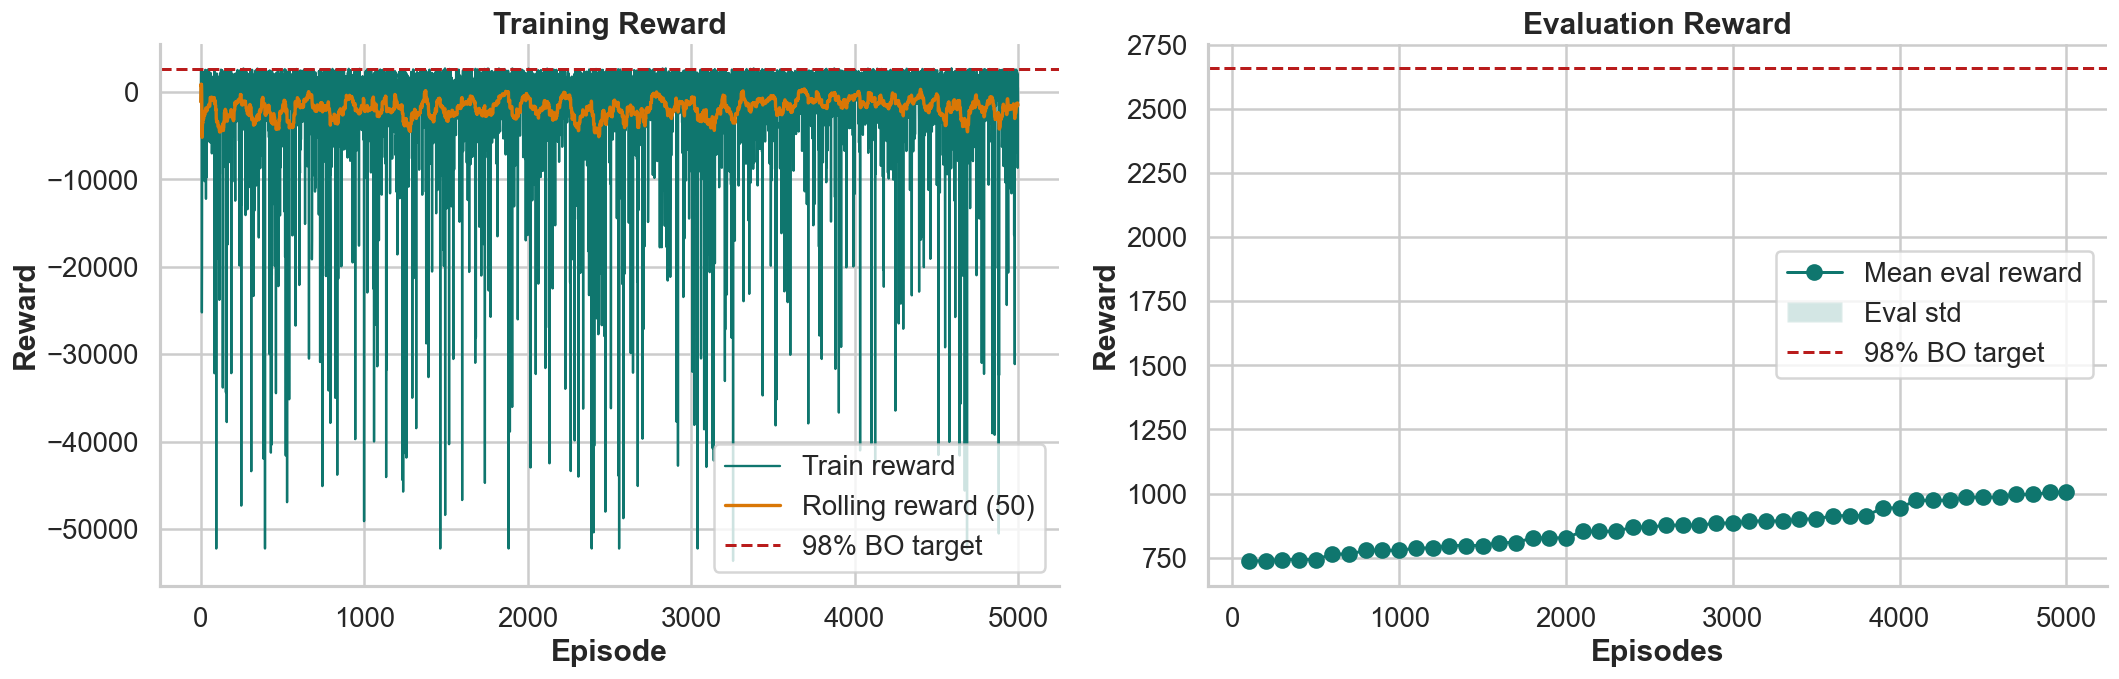

,path,size_mb,modified_time
0,/Users/campatzis/Documents/Research/runs/ppo_h...,1.603312,1.777435e+09
1,/Users/campatzis/Documents/Research/runs/ppo_h...,1.603311,1.777433e+09
2,/Users/campatzis/Documents/Research/runs/ppo_h...,1.603311,1.777431e+09
3,/Users/campatzis/Documents/Research/runs/ppo_h...,1.603311,1.777429e+09
4,/Users/campatzis/Documents/Research/runs/ppo_h...,1.603311,1.777428e+09
5,/Users/campatzis/Documents/Research/runs/ppo_h...,1.603298,1.777426e+09
6,/Users/campatzis/Documents/Research/runs/ppo_h...,1.603311,1.777424e+09
7,/Users/campatzis/Documents/Research/runs/ppo_h...,1.603311,1.777423e+09
8,/Users/campatzis/Documents/Research/runs/ppo_h...,1.603311,1.777420e+09
9,/Users/campatzis/Documents/Research/runs/ppo_h...,1.603297,1.777418e+09


In [6]:
train_history = load_monitor_frame(TRAIN_MONITOR_PATH)
eval_history = load_eval_frame(RUN_LOGDIR)

candidate_models = {
    "best_eval_model": BEST_MODEL_DIR / "best_model.zip",
    "final_model": RUN_LOGDIR / "final_model.zip",
}
analysis_rows = []
for label, path in candidate_models.items():
    if path.exists():
        row = evaluate_saved_model(path, n_eval_episodes=ANALYSIS_EVAL_EPISODES)
        row["label"] = label
        analysis_rows.append(row)

analysis_frame = pd.DataFrame(analysis_rows)
if not analysis_frame.empty:
    analysis_frame = analysis_frame.sort_values("mean_reward", ascending=False).reset_index(drop=True)
display(analysis_frame)

if not train_history.empty:
    latest_train = train_history.iloc[-1]
    train_summary = pd.DataFrame(
        [
            {
                "episodes": int(train_history["episode"].max()),
                "best_train_reward": float(train_history["reward"].max()),
                "best_train_fraction": fraction_of_bo(train_history["reward"].max()),
                "latest_train_reward": float(latest_train["reward"]),
                "latest_train_fraction": fraction_of_bo(latest_train["reward"]),
                "rolling_train_reward": float(latest_train["rolling_reward"]),
                "rolling_train_fraction": fraction_of_bo(latest_train["rolling_reward"]),
            }
        ]
    )
    display(train_summary)
    display(train_history.tail(10))

if not eval_history.empty:
    latest_eval = eval_history.iloc[-1]
    eval_summary = pd.DataFrame(
        [
            {
                "eval_points": int(len(eval_history)),
                "best_mean_eval_reward": float(eval_history["mean_eval_reward"].max()),
                "best_mean_eval_fraction": fraction_of_bo(eval_history["mean_eval_reward"].max()),
                "latest_mean_eval_reward": float(latest_eval["mean_eval_reward"]),
                "latest_mean_eval_fraction": float(latest_eval["mean_eval_fraction"]),
                "target_reached": bool(eval_history["mean_eval_reward"].max() >= SUCCESS_REWARD),
            }
        ]
    )
    display(eval_summary)
    display(eval_history.tail(10))

plot_ppo_diagnostics(train_history, eval_history)

checkpoint_rows = []
for path in sorted(CHECKPOINT_DIR.glob("*.zip")):
    checkpoint_rows.append(
        {
            "path": str(path),
            "size_mb": path.stat().st_size / (1024 * 1024),
            "modified_time": path.stat().st_mtime,
        }
    )
checkpoint_frame = pd.DataFrame(checkpoint_rows)
if not checkpoint_frame.empty:
    checkpoint_frame = checkpoint_frame.sort_values("modified_time", ascending=False).reset_index(drop=True)
display(checkpoint_frame.head(10))

## Readout

Use the `best_eval_model` row as the cleanest answer to the research question. If its `mean_fraction_of_bo` is at least `0.98`, then PPO met the target under the same one-shot reward contract used by the BO and Dreamer notebooks.